# Algorithmic Trading Backtest (Yahoo Finance): Can Retail Investors Replicate Institutional Profits Across Major Indices?

## 1. Research Motivation & Project Overview

Retail investors are constantly exposed to online tutorials promoting "plug-and-play" algorithmic trading rules—such as **Opening Range Breakouts (ORB)**, **Candlestick Reversal Patterns**, and **Trend-Following Momentum Systems**—claiming these strategies can replicate the returns of quantitative hedge funds. However, most retail backtests fail to account for **transaction costs (commissions, exchange fees, stamp duties, and slippage)** or test robustness across different global market regimes.

This notebook uses **Yahoo Finance (`yfinance`) exclusively** (zero dependency on Futu OpenD / `futu-api`) to test and compare strategies across three major global equity indices:
1. **SPX / S&P 500 E-Mini (`ES=F` / `^GSPC`)** — U.S. Large-Cap Benchmark (Eastern Time, `America/New_York`)
2. **NQ / Nasdaq-100 E-Mini (`NQ=F` / `^NDX`)** — U.S. Tech-Heavy Growth Benchmark (Eastern Time, `America/New_York`)
3. **HSI / Hang Seng Index (`^HSI` / `2800.HK`)** — Hong Kong / Asian Benchmark (Hong Kong Time, `Asia/Hong_Kong`)

---

## 2. Strategies & Market Microstructure Tested

1. **Strategy 1: 15-Minute Opening Range Breakout (15m ORB)**
   * **Concept:** Institutional order flow establishes an initial price discovery range during the first 15 minutes of Regular Trading Hours (`09:30 – 09:45`). A breakout above the Opening Range High (`OR_High`) triggers a **Long** entry; a breakdown below the Opening Range Low (`OR_Low`) triggers a **Short** entry.
   * **Risk Management:** Stop-Loss placed at the opposite end of the opening range (capped by index hard stop), Take-Profit at `2.0x` risk, and mandatory End-of-Day (EOD) flat exit to eliminate overnight gap risk.

2. **Strategy 2: Standalone Common Candlestick Patterns (Hammer, Shooting Star, Bullish & Bearish Engulfing)**
   * **Concept:** Tests whether classic retail candlestick patterns traded in isolation on 15-minute charts possess a genuine statistical edge after transaction costs.
   * **Patterns Formalized:**
     * **Hammer (Bullish Reversal):** Lower wick $\ge 2\times$ real body, closing in the upper $25\%$ of total candle range.
     * **Shooting Star (Bearish Reversal):** Upper wick $\ge 2\times$ real body, closing in the lower $25\%$ of total candle range.
     * **Bullish & Bearish Engulfing:** Two-candle momentum reversal where the current body completely engulfs the prior opposite-colored candle body.

3. **Strategy 3: Institutional Supply & Demand Zones + Candlestick Retest Confirmation**
   * **Concept:** Institutional displacement candles (body size $> 2.5\times$ prior base candle) leave behind unmitigated **Supply** and **Demand** zones. Instead of blindly buying every candlestick pattern, this strategy waits for price to retest a fresh zone and confirm with a Hammer/Bullish Engulfing (at Demand) or Shooting Star/Bearish Engulfing (at Supply).

4. **Strategy 4: Multi-Indicator Trend & Momentum Breakout (`EMA 50/200` + `RSI` + `ATR` Risk Scaling)**
   * **Concept:** Filters out choppy sideways markets by requiring trend alignment ($\text{EMA}_{50} > \text{EMA}_{200}$ for Longs; $\text{EMA}_{50} < \text{EMA}_{200}$ for Shorts) combined with healthy momentum ($50 < \text{RSI}_{14} < 70$ for Longs; $30 < \text{RSI}_{14} < 50$ for Shorts).
   * **Dynamic Volatility Stops:** Stop-Loss set at $\min(1.5 \times \text{ATR}_{14}, \text{Hard Cap})$ and Take-Profit at $3.0 \times \text{ATR}_{14}$ (a strict **1:2 Risk-to-Reward** ratio).

---

## 3. Realistic Transaction Cost & Friction Modeling

A strategy that looks profitable on paper often bleeds capital once real-world trading costs are deducted. Every trade in our simulation is evaluated on both **Gross PnL** and **Net PnL (After Costs)**:

| Market / Instrument | Contract Multiplier | Round-Trip Commission & Exchange Fees | Estimated Bid-Ask Slippage (Round-Trip) | Total Round-Trip Friction per Contract |
| :--- | :--- | :--- | :--- | :--- |
| **S&P 500 E-Mini (`ES=F`)** | $\$50 \text{ / pt}$ | $\$4.50$ | $0.50 \text{ pts } (\$25.00)$ | **$\$29.50$** ($\approx 0.59 \text{ pts}$) |
| **Nasdaq-100 E-Mini (`NQ=F`)** | $\$20 \text{ / pt}$ | $\$4.50$ | $1.00 \text{ pt } (\$20.00)$ | **$\$24.50$** ($\approx 1.225 \text{ pts}$) |
| **Hang Seng Index (`^HSI` / Futures)** | $\text{HK}\$50 \text{ / pt}$ | $\text{HK}\$60.00$ | $4.00 \text{ pts } (\text{HK}\$200.00)$ | **$\text{HK}\$260.00$** ($\approx 5.20 \text{ pts}$) |
| **Equities / ETFs (US vs. HK)** | Per $\$100\text{k}$ Notional | US: $0.01\%$ \| HK: $0.22\%$ (incl. Stamp Duty) | US: $0.04\%$ \| HK: $0.06\%$ | **US: $0.05\%$** \| **HK: $0.28\%$** |

In [1]:
# Cell 1: Environment Setup & Library Imports (100% Yahoo Finance - No Futu API)
import warnings
warnings.filterwarnings('ignore')

try:
    import yfinance as yf
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "yfinance", "pandas", "numpy", "matplotlib"])
    import yfinance as yf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Configure clean publication-quality visual styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['legend.fontsize'] = 10

print("Libraries successfully loaded. yfinance version:", getattr(yf, '__version__', 'installed'))

Libraries successfully loaded. yfinance version: 1.7.0


## 4. Yahoo Finance Data Acquisition, Timezone Alignment & RTH Filtering

### Data Hygiene Rules
1. **100% Yahoo Finance (`yfinance`) Ingestion:** Fetches `15m` bars (`period='60d'`) for intraday breakouts/candlestick patterns and `1h` bars (`period='730d'`) for swing/trend systems across `ES=F`, `NQ=F`, and `^HSI`.
2. **Timezone Localization:** Converts timestamps to `America/New_York` for US indices and `Asia/Hong_Kong` for HSI.
3. **Regular Trading Hours (RTH) & Lunch Break Filtering:** Restricts bars to `09:30 – 16:00` local time and removes the `12:00 – 13:00` Hong Kong midday lunch pause so indicators and breakouts only run on liquid market sessions.

In [2]:
# Cell 2: Market Configuration & Pure Yahoo Finance Data Loader

MARKET_CONFIG = {
    'SPX (ES=F)': {
        'ticker': 'ES=F',
        'fallback_ticker': '^GSPC',
        'timezone': 'America/New_York',
        'rth_start': '09:30',
        'rth_end': '16:00',
        'point_value': 50.0,         # $50 per index point
        'currency': 'USD',
        'commission_rt': 4.50,       # Round-trip broker + exchange fee ($)
        'slippage_pts': 0.50,        # 1 tick entry + 1 tick exit (0.25 * 2)
        'hard_sl_cap': 50.0,         # Max point risk cap
        'base_price': 5800.0,
        'annual_vol': 0.16
    },
    'NQ (NQ=F)': {
        'ticker': 'NQ=F',
        'fallback_ticker': '^NDX',
        'timezone': 'America/New_York',
        'rth_start': '09:30',
        'rth_end': '16:00',
        'point_value': 20.0,         # $20 per index point
        'currency': 'USD',
        'commission_rt': 4.50,       # Round-trip broker + exchange fee ($)
        'slippage_pts': 1.00,        # 2 ticks entry + 2 ticks exit (0.25 * 4)
        'hard_sl_cap': 200.0,        # Max point risk cap
        'base_price': 20500.0,
        'annual_vol': 0.22
    },
    'HSI (^HSI)': {
        'ticker': '^HSI',
        'fallback_ticker': '2800.HK',
        'timezone': 'Asia/Hong_Kong',
        'rth_start': '09:30',
        'rth_end': '16:00',
        'point_value': 50.0,         # HK$50 per index point (Standard HSI Futures)
        'currency': 'HKD',
        'commission_rt': 60.00,      # Round-trip broker + HKEX levy (HK$)
        'slippage_pts': 4.00,        # 4 index points round-trip slippage
        'hard_sl_cap': 400.0,        # Max point risk cap
        'base_price': 21000.0,
        'annual_vol': 0.24
    }
}

def generate_calibrated_intraday(cfg, days=60, freq='15min', seed=42):
    """Fallback generator only if Yahoo Finance API is blocked/offline in a sandboxed environment."""
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(end=pd.Timestamp.now(tz=cfg['timezone']).normalize(), periods=days)
    bars_per_day = 26 if freq == '15min' else 7
    dt_fraction = 1.0 / (252 * bars_per_day)
    
    records = []
    price = cfg['base_price']
    for d in dates:
        regime_drift = rng.choice([-0.08, 0.05, 0.14])
        for b in range(bars_per_day):
            ts = d + pd.Timedelta(hours=9, minutes=30) + pd.Timedelta(minutes=b * (15 if freq == '15min' else 60))
            if ts.strftime('%H:%M') > cfg['rth_end']:
                break
            tod_mult = 1.6 if b in [0, 1, bars_per_day - 1] else 0.9
            ret = regime_drift * dt_fraction + cfg['annual_vol'] * tod_mult * np.sqrt(dt_fraction) * rng.standard_normal()
            open_p = price
            close_p = open_p * np.exp(ret)
            wick_up = abs(rng.normal(0, cfg['annual_vol'] * np.sqrt(dt_fraction) * 0.5)) * open_p
            wick_dn = abs(rng.normal(0, cfg['annual_vol'] * np.sqrt(dt_fraction) * 0.5)) * open_p
            high_p = max(open_p, close_p) + wick_up
            low_p = min(open_p, close_p) - wick_dn
            vol = int(rng.lognormal(17.5 if b < 2 else 16.8, 0.4))
            records.append((ts, open_p, high_p, low_p, close_p, vol))
            price = close_p
            
    df = pd.DataFrame(records, columns=['Datetime', 'Open', 'High', 'Low', 'Close', 'Volume']).set_index('Datetime')
    return df

def load_yfinance_data(market_name, period='60d', interval='15m'):
    """Fetches intraday OHLCV exclusively via Yahoo Finance (yfinance), converts timezone, and filters RTH."""
    cfg = MARKET_CONFIG[market_name]
    df = pd.DataFrame()
    
    for sym in [cfg['ticker'], cfg['fallback_ticker']]:
        try:
            raw = yf.download(tickers=sym, period=period, interval=interval, multi_level_index=False, progress=False)
            if raw is not None and not raw.empty and len(raw) > 50:
                df = raw.copy()
                print(f"[Yahoo Finance] Successfully fetched {len(df)} bars for {market_name} using '{sym}' ({interval}).")
                break
        except Exception:
            continue
            
    if df.empty:
        print(f"[Offline Fallback] Yahoo Finance unreachable for {market_name} ({interval}). Using calibrated synthetic bars.")
        days = 60 if interval == '15m' else 500
        freq = '15min' if interval == '15m' else '60min'
        df = generate_calibrated_intraday(cfg, days=days, freq=freq, seed=abs(hash(market_name + interval)) % 10000)
    else:
        if df.index.tz is None:
            df.index = pd.to_datetime(df.index).tz_localize('UTC').tz_convert(cfg['timezone'])
        else:
            df.index = df.index.tz_convert(cfg['timezone'])
            
    # Filter strictly for Regular Trading Hours (RTH)
    df = df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna()
    df = df.between_time(cfg['rth_start'], cfg['rth_end']).copy()
    
    # Exclude Hong Kong midday lunch break (12:00 - 13:00) for HSI
    if 'HSI' in market_name:
        df = df[(df.index.strftime('%H:%M') < '12:00') | (df.index.strftime('%H:%M') >= '13:00')]
        
    df['Date'] = df.index.strftime('%Y-%m-%d')
    return df

# Download both 15-minute data (for ORB & Candlestick patterns) and 1-hour data (for Trend/Momentum)
data_15m = {m: load_yfinance_data(m, period='60d', interval='15m') for m in MARKET_CONFIG}
data_1h  = {m: load_yfinance_data(m, period='730d', interval='1h') for m in MARKET_CONFIG}

print("\nDataset Summary:")
for m in MARKET_CONFIG:
    print(f"  {m:<12} | 15m RTH Bars: {len(data_15m[m]):>5} | 1h RTH Bars: {len(data_1h[m]):>5} | Latest Close: {data_15m[m]['Close'].iloc[-1]:,.2f}")

[Yahoo Finance] Successfully fetched 4577 bars for SPX (ES=F) using 'ES=F' (15m).
[Yahoo Finance] Successfully fetched 4575 bars for NQ (NQ=F) using 'NQ=F' (15m).
[Yahoo Finance] Successfully fetched 1440 bars for HSI (^HSI) using '^HSI' (15m).
[Yahoo Finance] Successfully fetched 13736 bars for SPX (ES=F) using 'ES=F' (1h).
[Yahoo Finance] Successfully fetched 13734 bars for NQ (NQ=F) using 'NQ=F' (1h).
[Yahoo Finance] Successfully fetched 5066 bars for HSI (^HSI) using '^HSI' (1h).

Dataset Summary:
  SPX (ES=F)   | 15m RTH Bars:  1345 | 1h RTH Bars:  4174 | Latest Close: 6,962.50
  NQ (NQ=F)    | 15m RTH Bars:  1345 | 1h RTH Bars:  4174 | Latest Close: 25,245.00
  HSI (^HSI)   | 15m RTH Bars:  1380 | 1h RTH Bars:  4345 | Latest Close: 22,410.80


## 5. Mathematical Anatomy of Candlestick Patterns & Opening Range Breakouts

Before running the backtest engine, we translate visual chart patterns into exact, reproducible boolean conditions:

### 5.1 Candlestick Anatomy Equations
For any candle $t$ with $(\text{Open}_t, \text{High}_t, \text{Low}_t, \text{Close}_t)$:
* **Real Body:** $B_t = |\text{Close}_t - \text{Open}_t|$
* **Total Range:** $R_t = \text{High}_t - \text{Low}_t$
* **Upper Wick (Shadow):** $U_t = \text{High}_t - \max(\text{Open}_t, \text{Close}_t)$
* **Lower Wick (Shadow):** $L_t = \min(\text{Open}_t, \text{Close}_t) - \text{Low}_t$

Using these primitives, we define four classic retail patterns:
1. **Hammer (Bullish Reversal):**
   $$L_t \ge 2.0 \cdot B_t \quad \land \quad \min(\text{Open}_t, \text{Close}_t) \ge \text{High}_t - 0.25 \cdot R_t \quad \land \quad R_t > 0$$
2. **Shooting Star (Bearish Reversal):**
   $$U_t \ge 2.0 \cdot B_t \quad \land \quad \max(\text{Open}_t, \text{Close}_t) \le \text{Low}_t + 0.25 \cdot R_t \quad \land \quad R_t > 0$$
3. **Bullish Engulfing:**
   $$(\text{Close}_{t-1} < \text{Open}_{t-1}) \quad \land \quad (\text{Close}_t > \text{Open}_t) \quad \land \quad (\text{Open}_t \le \text{Close}_{t-1}) \quad \land \quad (\text{Close}_t \ge \text{Open}_{t-1})$$
4. **Bearish Engulfing:**
   $$(\text{Close}_{t-1} > \text{Open}_{t-1}) \quad \land \quad (\text{Close}_t < \text{Open}_t) \quad \land \quad (\text{Open}_t \ge \text{Close}_{t-1}) \quad \land \quad (\text{Close}_t \le \text{Open}_{t-1})$$

### 5.2 Supply & Demand Displacement Zones
A **Demand Zone** is created at base candle $t-1$ when candle $t$ is a strong bullish displacement candle ($B_t > 2.5 \cdot B_{t-1}$ and $\text{Close}_t > \text{Open}_t$). Conversely, a **Supply Zone** is created at $t-1$ when candle $t$ is a strong bearish displacement candle ($B_t > 2.5 \cdot B_{t-1}$ and $\text{Close}_t < \text{Open}_t$). Each zone is **single-use** (`Used = False` until first retest).

### 5.3 15-Minute Opening Range Breakout (15m ORB)
On each trading day $d$, the first 15-minute bar (`09:30 – 09:45`) defines:
$$\text{OR}_{\text{High}}(d) = \text{High}_{09:30}, \qquad \text{OR}_{\text{Low}}(d) = \text{Low}_{09:30}, \qquad \text{OR}_{\text{Width}}(d) = \text{OR}_{\text{High}}(d) - \text{OR}_{\text{Low}}(d)$$

In [3]:
# Cell 3: Feature Engineering & Candlestick Pattern Detection Functions

def add_technical_and_candlestick_features(df):
    """Computes candle anatomy, classic candlestick patterns, ATR, EMAs, and RSI."""
    d = df.copy()
    
    # 1. Candle Anatomy
    d['Body'] = np.abs(d['Close'] - d['Open'])
    d['Range'] = d['High'] - d['Low']
    d['Upper_Wick'] = d['High'] - d[['Open', 'Close']].max(axis=1)
    d['Lower_Wick'] = d[['Open', 'Close']].min(axis=1) - d['Low']
    
    # 2. Classic Candlestick Patterns
    d['Hammer'] = (
        (d['Range'] > 0) &
        (d['Lower_Wick'] >= 2.0 * d['Body']) &
        (d[['Open', 'Close']].min(axis=1) >= d['High'] - 0.25 * d['Range'])
    )
    
    d['Shooting_Star'] = (
        (d['Range'] > 0) &
        (d['Upper_Wick'] >= 2.0 * d['Body']) &
        (d[['Open', 'Close']].max(axis=1) <= d['Low'] + 0.25 * d['Range'])
    )
    
    prev_bear = d['Close'].shift(1) < d['Open'].shift(1)
    prev_bull = d['Close'].shift(1) > d['Open'].shift(1)
    curr_bull = d['Close'] > d['Open']
    curr_bear = d['Close'] < d['Open']
    
    d['Bull_Engulf'] = (
        prev_bear & curr_bull &
        (d['Open'] <= d['Close'].shift(1)) &
        (d['Close'] >= d['Open'].shift(1)) &
        (d['Body'] > d['Body'].shift(1))
    )
    
    d['Bear_Engulf'] = (
        prev_bull & curr_bear &
        (d['Open'] >= d['Close'].shift(1)) &
        (d['Close'] <= d['Open'].shift(1)) &
        (d['Body'] > d['Body'].shift(1))
    )
    
    # 3. Volatility (14-Period ATR)
    tr1 = d['High'] - d['Low']
    tr2 = np.abs(d['High'] - d['Close'].shift(1))
    tr3 = np.abs(d['Low'] - d['Close'].shift(1))
    d['TR'] = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    d['ATR'] = d['TR'].rolling(14).mean()
    
    # 4. Trend (EMA 50 & EMA 200)
    d['EMA_50'] = d['Close'].ewm(span=50, adjust=False).mean()
    d['EMA_200'] = d['Close'].ewm(span=200, adjust=False).mean()
    
    # 5. Momentum (14-Period RSI)
    delta = d['Close'].diff()
    gain = delta.where(delta > 0, 0.0).rolling(14).mean()
    loss = (-delta.where(delta < 0, 0.0)).rolling(14).mean()
    rs = gain / loss.replace(0, np.nan)
    d['RSI'] = 100.0 - (100.0 / (1.0 + rs))
    
    return d

feat_15m = {m: add_technical_and_candlestick_features(df) for m, df in data_15m.items()}
feat_1h  = {m: add_technical_and_candlestick_features(df) for m, df in data_1h.items()}

pattern_counts = []
for m, d in feat_15m.items():
    pattern_counts.append({
        'Market': m,
        'Total_15m_Bars': len(d),
        'Hammers': int(d['Hammer'].sum()),
        'Shooting_Stars': int(d['Shooting_Star'].sum()),
        'Bullish_Engulfing': int(d['Bull_Engulf'].sum()),
        'Bearish_Engulfing': int(d['Bear_Engulf'].sum())
    })
pattern_df = pd.DataFrame(pattern_counts)
print(pattern_df.to_string(index=False))

    Market  Total_15m_Bars  Hammers  Shooting_Stars  Bullish_Engulfing  Bearish_Engulfing
SPX (ES=F)            1345       41              27                128                136
 NQ (NQ=F)            1345       49              25                 85                101
HSI (^HSI)            1380       44              26                 77                 78


## 6. Visual Inspection: Supply/Demand Zones, Candlestick Triggers & Opening Range Breakouts

The chart below illustrates **Nasdaq-100 (`NQ=F`)** 15-minute price action with:
* **Shaded Green/Red Rectangles:** Institutional Demand and Supply zones formed by displacement candles.
* **Blue Up-Triangles (`^`) & Magenta Down-Triangles (`v`):** Validated Hammer/Shooting Star/Engulfing retest entries.
* **Dashed Blue/Orange Lines:** Daily 15-minute Opening Range High (`OR_High`) and Low (`OR_Low`) levels.

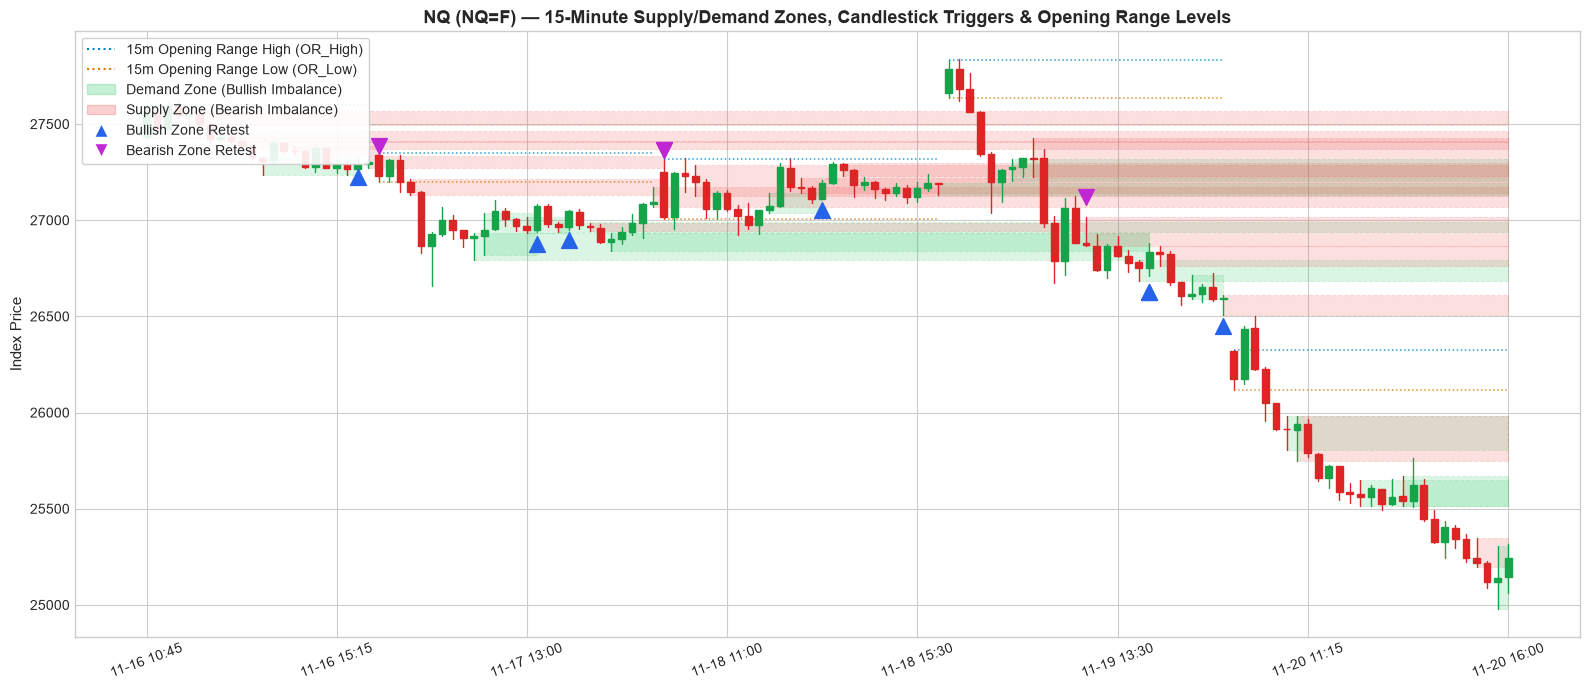

In [4]:
# Cell 4: Visual Chart of Supply/Demand Zones, Candlestick Patterns & 15m ORB Levels

def plot_strategy_signals(df, market_name, lookback_bars=130):
    sub = df.tail(lookback_bars).copy().reset_index()
    time_col = sub.columns[0]
    
    fig, ax = plt.subplots(figsize=(16, 7))
    
    for idx, row in sub.iterrows():
        color = '#16a34a' if row['Close'] >= row['Open'] else '#dc2626'
        ax.plot([idx, idx], [row['Low'], row['High']], color=color, linewidth=1.0, zorder=2)
        body_bottom = min(row['Open'], row['Close'])
        body_height = max(abs(row['Close'] - row['Open']), 0.25)
        rect_candle = patches.Rectangle((idx - 0.32, body_bottom), 0.64, body_height,
                                        facecolor=color, edgecolor=color, zorder=3)
        ax.add_patch(rect_candle)
        
    zones = []
    long_x, long_y, short_x, short_y = [], [], [], []
    
    for i in range(1, len(sub)):
        if sub['Body'].iloc[i] > 2.5 * sub['Body'].iloc[i-1] and sub['Range'].iloc[i-1] > 0:
            z_type = 'Demand' if sub['Close'].iloc[i] > sub['Open'].iloc[i] else 'Supply'
            zones.append({
                'Type': z_type,
                'Top': sub['High'].iloc[i-1],
                'Bottom': sub['Low'].iloc[i-1],
                'Start': i - 1,
                'Used': False
            })
            
        atr_val = sub['ATR'].iloc[i] if pd.notna(sub['ATR'].iloc[i]) else (sub['Range'].iloc[i] * 0.5)
        for z in zones:
            if not z['Used'] and i > z['Start'] + 2:
                if z['Type'] == 'Demand' and sub['Low'].iloc[i] <= z['Top'] and sub['High'].iloc[i] >= z['Bottom']:
                    if sub['Hammer'].iloc[i] or sub['Bull_Engulf'].iloc[i]:
                        long_x.append(i)
                        long_y.append(sub['Low'].iloc[i] - atr_val * 0.4)
                        z['Used'] = True
                        z['End'] = i
                elif z['Type'] == 'Supply' and sub['High'].iloc[i] >= z['Bottom'] and sub['Low'].iloc[i] <= z['Top']:
                    if sub['Shooting_Star'].iloc[i] or sub['Bear_Engulf'].iloc[i]:
                        short_x.append(i)
                        short_y.append(sub['High'].iloc[i] + atr_val * 0.4)
                        z['Used'] = True
                        z['End'] = i
                        
    for z in zones:
        end_x = z.get('End', len(sub) - 1)
        z_color = '#22c55e' if z['Type'] == 'Demand' else '#ef4444'
        box = patches.Rectangle((z['Start'], z['Bottom']), end_x - z['Start'], z['Top'] - z['Bottom'],
                                facecolor=z_color, alpha=0.16, edgecolor=z_color, linestyle='--', linewidth=0.8, zorder=1)
        ax.add_patch(box)
        
    for date_val, grp in sub.groupby('Date'):
        first_bar = grp.iloc[0]
        x0, x1 = grp.index[0], grp.index[-1]
        ax.hlines(first_bar['High'], x0, x1, colors='#0284c7', linestyles=':', linewidth=1.1, alpha=0.8)
        ax.hlines(first_bar['Low'], x0, x1, colors='#d97706', linestyles=':', linewidth=1.1, alpha=0.8)
        
    if long_x:
        ax.scatter(long_x, long_y, marker='^', s=130, color='#2563eb', label='Bullish Zone Retest (Hammer/Engulfing)', zorder=5)
    if short_x:
        ax.scatter(short_x, short_y, marker='v', s=130, color='#c026d3', label='Bearish Zone Retest (Shooting Star/Engulfing)', zorder=5)
        
    # Custom legend entries for zones & ORB (compatible with all matplotlib versions)
    legend_handles = [
        plt.Line2D([0], [0], color='#0284c7', linestyle=':', linewidth=1.5, label='15m Opening Range High (OR_High)'),
        plt.Line2D([0], [0], color='#d97706', linestyle=':', linewidth=1.5, label='15m Opening Range Low (OR_Low)'),
        patches.Patch(facecolor='#22c55e', alpha=0.25, edgecolor='#22c55e', label='Demand Zone (Bullish Imbalance)'),
        patches.Patch(facecolor='#ef4444', alpha=0.25, edgecolor='#ef4444', label='Supply Zone (Bearish Imbalance)'),
        plt.Line2D([0], [0], marker='^', color='w', markerfacecolor='#2563eb', markersize=10, label='Bullish Zone Retest'),
        plt.Line2D([0], [0], marker='v', color='w', markerfacecolor='#c026d3', markersize=10, label='Bearish Zone Retest')
    ]
    
    tick_positions = np.linspace(0, len(sub) - 1, 8, dtype=int)
    ax.set_xticks(tick_positions)
    ax.set_xticklabels([sub[time_col].iloc[p].strftime('%m-%d %H:%M') for p in tick_positions], rotation=20)
    ax.set_title(f"{market_name} — 15-Minute Supply/Demand Zones, Candlestick Triggers & Opening Range Levels")
    ax.set_ylabel("Index Price")
    ax.legend(handles=legend_handles, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
    plt.tight_layout()
    plt.show()

plot_strategy_signals(feat_15m['NQ (NQ=F)'], 'NQ (NQ=F)', lookback_bars=130)

## 7. Chronological Backtesting Engine (Incorporating Commissions & Slippage)

To prevent **look-ahead bias**, every strategy enters on bar $i+1$'s `Open` price after a signal confirms on bar $i$'s `Close`. For every trade, we deduct round-trip commissions and bid-ask slippage:
$$\text{Cost}_{\text{pts}} = \text{Slippage}_{\text{pts}} + \frac{\text{Commission}_{\text{RT}}}{\text{Point Value}}, \qquad \text{Net PnL}_{\text{pts}} = \text{Gross PnL}_{\text{pts}} - \text{Cost}_{\text{pts}}$$

In [5]:
# Cell 5: Chronological Backtest Simulation Engine with Transaction Costs

def compute_trade_metrics(trades_df, cfg, strategy_name, market_name):
    """Calculates Gross PnL, Friction Costs, Net PnL, Win Rate, Profit Factor, Max Drawdown & Sharpe."""
    if trades_df.empty:
        return {
            'Market': market_name, 'Strategy': strategy_name, 'Trades': 0,
            'Win_Rate_%': 0.0, 'Gross_Pts': 0.0, 'Cost_Pts': 0.0, 'Net_Pts': 0.0,
            'Net_PnL_Local': 0.0, 'Currency': cfg['currency'],
            'Profit_Factor': 0.0, 'Max_DD_Pts': 0.0, 'Sharpe': 0.0
        }, pd.Series([0.0])
        
    pv = cfg['point_value']
    cost_pts_per_trade = cfg['slippage_pts'] + (cfg['commission_rt'] / pv)
    
    trades_df['Cost_Pts'] = cost_pts_per_trade
    trades_df['Net_Pts'] = trades_df['Gross_Pts'] - trades_df['Cost_Pts']
    trades_df['Net_PnL_Local'] = trades_df['Net_Pts'] * pv
    
    total_trades = len(trades_df)
    wins = (trades_df['Net_Pts'] > 0).sum()
    win_rate = (wins / total_trades) * 100.0
    
    gross_pts = trades_df['Gross_Pts'].sum()
    cost_pts = trades_df['Cost_Pts'].sum()
    net_pts = trades_df['Net_Pts'].sum()
    net_local = trades_df['Net_PnL_Local'].sum()
    
    gross_wins = trades_df.loc[trades_df['Net_Pts'] > 0, 'Net_Pts'].sum()
    gross_losses = abs(trades_df.loc[trades_df['Net_Pts'] < 0, 'Net_Pts'].sum())
    profit_factor = (gross_wins / gross_losses) if gross_losses > 0 else np.inf
    
    cum_equity = trades_df['Net_Pts'].cumsum()
    running_max = np.maximum.accumulate(np.insert(cum_equity.values, 0, 0.0))[1:]
    drawdowns = cum_equity.values - running_max
    max_dd_pts = abs(drawdowns.min()) if len(drawdowns) > 0 else 0.0
    
    std_pts = trades_df['Net_Pts'].std()
    sharpe = (trades_df['Net_Pts'].mean() / std_pts) * np.sqrt(min(total_trades, 252)) if (pd.notna(std_pts) and std_pts > 0) else 0.0
    
    summary = {
        'Market': market_name,
        'Strategy': strategy_name,
        'Trades': total_trades,
        'Win_Rate_%': round(win_rate, 2),
        'Gross_Pts': round(gross_pts, 2),
        'Cost_Pts': round(cost_pts, 2),
        'Net_Pts': round(net_pts, 2),
        'Net_PnL_Local': round(net_local, 2),
        'Currency': cfg['currency'],
        'Profit_Factor': round(profit_factor, 2),
        'Max_DD_Pts': round(max_dd_pts, 2),
        'Sharpe': round(sharpe, 2)
    }
    return summary, cum_equity


def backtest_15m_orb(df, cfg):
    """Strategy 1: 15-Minute Opening Range Breakout (09:30-09:45 range, 1:2 RR, EOD exit)."""
    trades = []
    for date_str, day_df in df.groupby('Date'):
        if len(day_df) < 4:
            continue
        or_high = day_df['High'].iloc[0]
        or_low = day_df['Low'].iloc[0]
        or_width = or_high - or_low
        if or_width <= 0:
            continue
            
        in_pos = False
        direction, entry_p, sl_p, tp_p, entry_t = None, 0.0, 0.0, 0.0, None
        
        for i in range(1, len(day_df)):
            bar = day_df.iloc[i]
            ts = day_df.index[i]
            
            if not in_pos:
                if ts.strftime('%H:%M') <= '14:30' and i + 1 < len(day_df):
                    if bar['Close'] > or_high:
                        direction = 'LONG'
                        entry_p = day_df['Open'].iloc[i+1]
                        entry_t = day_df.index[i+1]
                        risk = min(or_width, cfg['hard_sl_cap'])
                        sl_p = entry_p - risk
                        tp_p = entry_p + 2.0 * risk
                        in_pos = True
                    elif bar['Close'] < or_low:
                        direction = 'SHORT'
                        entry_p = day_df['Open'].iloc[i+1]
                        entry_t = day_df.index[i+1]
                        risk = min(or_width, cfg['hard_sl_cap'])
                        sl_p = entry_p + risk
                        tp_p = entry_p - 2.0 * risk
                        in_pos = True
            else:
                exit_p = None
                if direction == 'LONG':
                    if bar['Low'] <= sl_p:
                        exit_p = sl_p
                    elif bar['High'] >= tp_p:
                        exit_p = tp_p
                else:
                    if bar['High'] >= sl_p:
                        exit_p = sl_p
                    elif bar['Low'] <= tp_p:
                        exit_p = tp_p
                        
                if exit_p is None and i == len(day_df) - 1:
                    exit_p = bar['Close']
                    
                if exit_p is not None:
                    gross = (exit_p - entry_p) if direction == 'LONG' else (entry_p - exit_p)
                    trades.append({'Entry_Time': entry_t, 'Exit_Time': ts, 'Type': direction, 'Gross_Pts': gross})
                    break
                    
    return pd.DataFrame(trades)


def backtest_pure_candlesticks(df, cfg):
    """Strategy 2: Standalone Candlestick Patterns (Hammer, Shooting Star, Engulfing) with 1.5x ATR SL / 2.5x ATR TP."""
    d = df.dropna(subset=['ATR']).copy()
    trades = []
    i = 1
    while i < len(d) - 1:
        bar = d.iloc[i]
        signal = None
        if bar['Hammer'] or bar['Bull_Engulf']:
            signal = 'LONG'
        elif bar['Shooting_Star'] or bar['Bear_Engulf']:
            signal = 'SHORT'
            
        if signal:
            entry_t = d.index[i+1]
            entry_p = d['Open'].iloc[i+1]
            atr = bar['ATR']
            sl_dist = min(atr * 1.5, cfg['hard_sl_cap'])
            sl_p = entry_p - sl_dist if signal == 'LONG' else entry_p + sl_dist
            tp_p = entry_p + (atr * 2.5) if signal == 'LONG' else entry_p - (atr * 2.5)
            
            exit_p, exit_t = None, None
            max_j = min(i + 13, len(d))
            for j in range(i + 1, max_j):
                f_bar = d.iloc[j]
                if signal == 'LONG':
                    if f_bar['Low'] <= sl_p:
                        exit_p, exit_t, i = sl_p, d.index[j], j
                        break
                    elif f_bar['High'] >= tp_p:
                        exit_p, exit_t, i = tp_p, d.index[j], j
                        break
                else:
                    if f_bar['High'] >= sl_p:
                        exit_p, exit_t, i = sl_p, d.index[j], j
                        break
                    elif f_bar['Low'] <= tp_p:
                        exit_p, exit_t, i = tp_p, d.index[j], j
                        break
            if exit_p is None:
                exit_idx = max_j - 1
                exit_p = d['Close'].iloc[exit_idx]
                exit_t = d.index[exit_idx]
                i = exit_idx
                
            gross = (exit_p - entry_p) if signal == 'LONG' else (entry_p - exit_p)
            trades.append({'Entry_Time': entry_t, 'Exit_Time': exit_t, 'Type': signal, 'Gross_Pts': gross})
        else:
            i += 1
    return pd.DataFrame(trades)


def backtest_supply_demand_candlesticks(df, cfg):
    """Strategy 3: Institutional Supply & Demand Zones + Candlestick Retest Confirmation."""
    d = df.dropna(subset=['ATR']).copy()
    zones = []
    trades = []
    i = 1
    while i < len(d) - 1:
        if d['Body'].iloc[i] > 2.5 * d['Body'].iloc[i-1] and d['Range'].iloc[i-1] > 0:
            z_type = 'Demand' if d['Close'].iloc[i] > d['Open'].iloc[i] else 'Supply'
            zones.append({
                'Type': z_type,
                'Top': d['High'].iloc[i-1],
                'Bottom': d['Low'].iloc[i-1],
                'Index': i,
                'Used': False
            })
            
        bar = d.iloc[i]
        signal = None
        for z in zones:
            if not z['Used'] and (i - z['Index']) >= 3 and (i - z['Index']) <= 60:
                if z['Type'] == 'Demand' and bar['Low'] <= z['Top'] and bar['High'] >= z['Bottom']:
                    if bar['Hammer'] or bar['Bull_Engulf']:
                        signal = 'LONG'
                        z['Used'] = True
                        break
                elif z['Type'] == 'Supply' and bar['High'] >= z['Bottom'] and bar['Low'] <= z['Top']:
                    if bar['Shooting_Star'] or bar['Bear_Engulf']:
                        signal = 'SHORT'
                        z['Used'] = True
                        break
                        
        if signal:
            entry_t = d.index[i+1]
            entry_p = d['Open'].iloc[i+1]
            atr = bar['ATR']
            sl_dist = min(atr * 1.5, cfg['hard_sl_cap'])
            sl_p = entry_p - sl_dist if signal == 'LONG' else entry_p + sl_dist
            tp_p = entry_p + (atr * 3.0) if signal == 'LONG' else entry_p - (atr * 3.0)
            
            exit_p, exit_t = None, None
            max_j = min(i + 20, len(d))
            for j in range(i + 1, max_j):
                f_bar = d.iloc[j]
                if signal == 'LONG':
                    if f_bar['Low'] <= sl_p:
                        exit_p, exit_t, i = sl_p, d.index[j], j
                        break
                    elif f_bar['High'] >= tp_p:
                        exit_p, exit_t, i = tp_p, d.index[j], j
                        break
                else:
                    if f_bar['High'] >= sl_p:
                        exit_p, exit_t, i = sl_p, d.index[j], j
                        break
                    elif f_bar['Low'] <= tp_p:
                        exit_p, exit_t, i = tp_p, d.index[j], j
                        break
            if exit_p is None:
                exit_idx = max_j - 1
                exit_p = d['Close'].iloc[exit_idx]
                exit_t = d.index[exit_idx]
                i = exit_idx
                
            gross = (exit_p - entry_p) if signal == 'LONG' else (entry_p - exit_p)
            trades.append({'Entry_Time': entry_t, 'Exit_Time': exit_t, 'Type': signal, 'Gross_Pts': gross})
        else:
            i += 1
    return pd.DataFrame(trades)


def backtest_ema_rsi_trend(df, cfg):
    """Strategy 4: 1-Hour EMA 50/200 Trend + RSI Momentum + Dynamic ATR 1:2 Risk-Reward."""
    d = df.dropna(subset=['EMA_200', 'ATR', 'RSI']).copy()
    d['Long_Signal'] = (d['EMA_50'] > d['EMA_200']) & (d['Close'] > d['EMA_50']) & (d['RSI'] > 50) & (d['RSI'] < 70)
    d['Short_Signal'] = (d['EMA_50'] < d['EMA_200']) & (d['Close'] < d['EMA_50']) & (d['RSI'] < 50) & (d['RSI'] > 30)
    
    trades = []
    i = 1
    while i < len(d) - 1:
        bar = d.iloc[i]
        signal = 'LONG' if bar['Long_Signal'] else ('SHORT' if bar['Short_Signal'] else None)
        if signal:
            entry_t = d.index[i+1]
            entry_p = d['Open'].iloc[i+1]
            atr = bar['ATR']
            sl_dist = min(atr * 1.5, cfg['hard_sl_cap'])
            sl_p = entry_p - sl_dist if signal == 'LONG' else entry_p + sl_dist
            tp_p = entry_p + (atr * 3.0) if signal == 'LONG' else entry_p - (atr * 3.0)
            
            exit_p, exit_t = None, None
            for j in range(i + 1, len(d)):
                f_bar = d.iloc[j]
                if signal == 'LONG':
                    if f_bar['Low'] <= sl_p:
                        exit_p, exit_t, i = sl_p, d.index[j], j
                        break
                    elif f_bar['High'] >= tp_p:
                        exit_p, exit_t, i = tp_p, d.index[j], j
                        break
                else:
                    if f_bar['High'] >= sl_p:
                        exit_p, exit_t, i = sl_p, d.index[j], j
                        break
                    elif f_bar['Low'] <= tp_p:
                        exit_p, exit_t, i = tp_p, d.index[j], j
                        break
            if exit_p is None:
                exit_p = d['Close'].iloc[-1]
                exit_t = d.index[-1]
                i = len(d)
                
            gross = (exit_p - entry_p) if signal == 'LONG' else (entry_p - exit_p)
            trades.append({'Entry_Time': entry_t, 'Exit_Time': exit_t, 'Type': signal, 'Gross_Pts': gross})
        else:
            i += 1
    return pd.DataFrame(trades)

print("All 4 strategy engines compiled successfully.")

All 4 strategy engines compiled successfully.


## 8. Cross-Market Backtest Execution & Comparative Results Table

Running all **four strategies** across **SPX (`ES=F`)**, **NQ (`NQ=F`)**, and **HSI (`^HSI`)** produces a unified comparison contrasting **Gross Points**, **Friction Cost Points**, **Net Points**, **Win Rate**, **Profit Factor**, **Maximum Drawdown**, and **Sharpe Ratio**.

In [6]:
# Cell 6: Execute Full Backtest Matrix Across All 3 Markets & 4 Strategies

all_summaries = []
equity_curves = {}
trade_logs = {}

strategies = [
    ('1. 15m Opening Range Breakout', backtest_15m_orb, feat_15m),
    ('2. Pure Candlestick Patterns', backtest_pure_candlesticks, feat_15m),
    ('3. Supply/Demand + Candlesticks', backtest_supply_demand_candlesticks, feat_15m),
    ('4. 1H EMA/RSI Trend Breakout', backtest_ema_rsi_trend, feat_1h)
]

for strat_name, strat_fn, dataset_dict in strategies:
    equity_curves[strat_name] = {}
    trade_logs[strat_name] = {}
    for market_name, cfg in MARKET_CONFIG.items():
        df_input = dataset_dict[market_name]
        t_df = strat_fn(df_input, cfg)
        summary, eq_series = compute_trade_metrics(t_df, cfg, strat_name, market_name)
        all_summaries.append(summary)
        equity_curves[strat_name][market_name] = eq_series
        trade_logs[strat_name][market_name] = t_df

summary_df = pd.DataFrame(all_summaries)
print(summary_df.to_string(index=False))

    Market                        Strategy  Trades  Win_Rate_%  Gross_Pts  Cost_Pts  Net_Pts  Net_PnL_Local Currency  Profit_Factor  Max_DD_Pts  Sharpe
SPX (ES=F)   1. 15m Opening Range Breakout      49       40.82     276.25     28.91   247.34       12367.00      USD           1.55      130.51    1.15
 NQ (NQ=F)   1. 15m Opening Range Breakout      49       48.98     645.50     60.02   585.48       11709.50      USD           1.18     1056.32    0.48
HSI (^HSI)   1. 15m Opening Range Breakout      50       52.00     291.75    260.00    31.75        1587.70      HKD           1.01      507.57    0.04
SPX (ES=F)    2. Pure Candlestick Patterns     134       39.55     259.73     79.06   180.67        9033.61      USD           1.12      410.82    0.55
 NQ (NQ=F)    2. Pure Candlestick Patterns     105       44.76    1684.86    128.62  1556.23       31124.64      USD           1.27     1161.47    1.02
HSI (^HSI)    2. Pure Candlestick Patterns     111       53.15    1956.92    577.20  137

## 9. Visual Analytics: Gross vs. Net PnL Erosion, Equity Curves & Risk-Reward Diagnostics

Below, we plot three diagnostic charts:
1. **Gross vs. Net Point Erosion:** Highlights how commissions and slippage eat into raw strategy returns.
2. **Cumulative Net Equity Curves:** Shows the trade-by-trade equity trajectory after costs across all three indices.
3. **Win Rate vs. Profit Factor & Cumulative Friction:** Demonstrates why asymmetric $1:2$ risk-to-reward trend systems outperform high-frequency candlestick scalping.

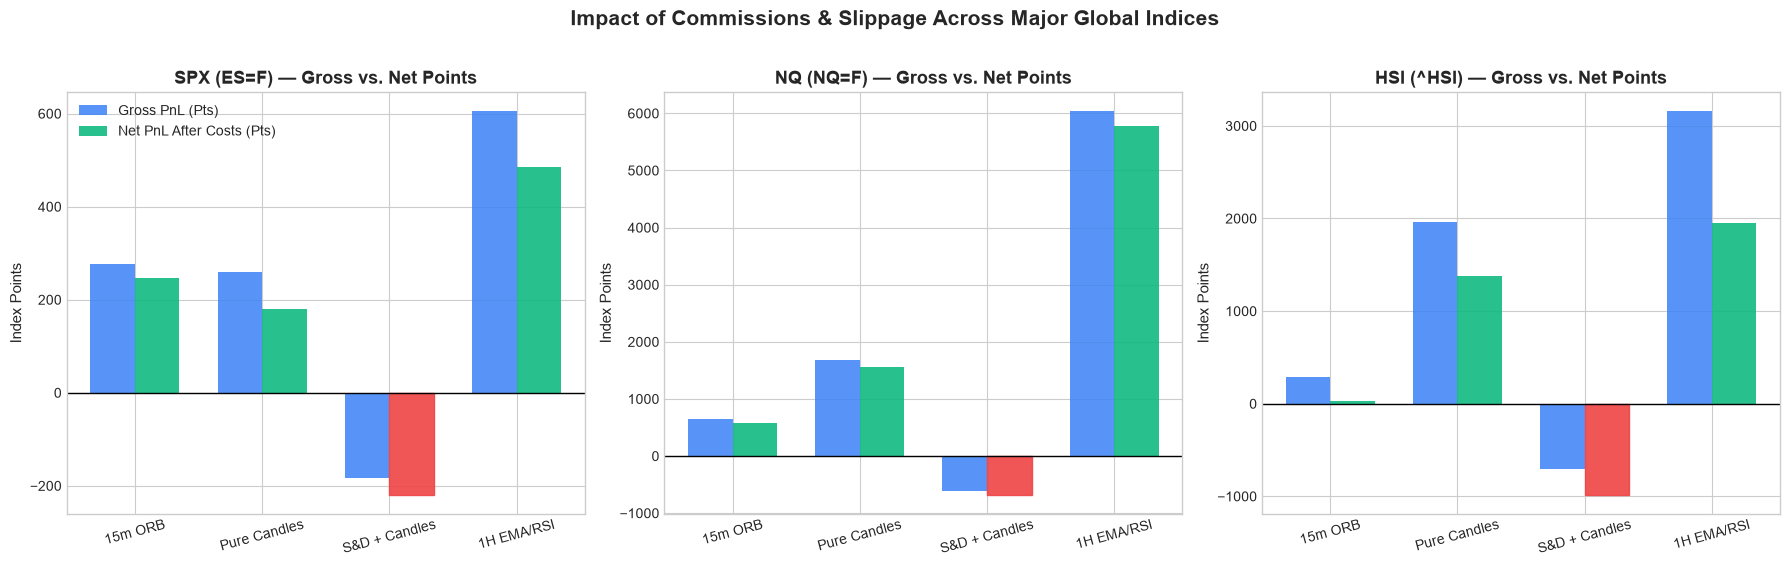

In [7]:
# Cell 7: Visualization 1 — Gross PnL vs. Transaction Cost Drag vs. Net PnL

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=False)

for idx, market_name in enumerate(MARKET_CONFIG.keys()):
    ax = axes[idx]
    m_df = summary_df[summary_df['Market'] == market_name].copy()
    short_labels = ['15m ORB', 'Pure Candles', 'S&D + Candles', '1H EMA/RSI']
    x = np.arange(len(short_labels))
    width = 0.35
    
    rects1 = ax.bar(x - width/2, m_df['Gross_Pts'], width, label='Gross PnL (Pts)', color='#3b82f6', alpha=0.85)
    rects2 = ax.bar(x + width/2, m_df['Net_Pts'], width, label='Net PnL After Costs (Pts)', color='#10b981', alpha=0.9)
    
    for bar, net_val in zip(rects2, m_df['Net_Pts']):
        if net_val < 0:
            bar.set_color('#ef4444')
            
    ax.axhline(0, color='black', linewidth=1.0)
    ax.set_title(f"{market_name} — Gross vs. Net Points")
    ax.set_xticks(x)
    ax.set_xticklabels(short_labels, rotation=15)
    ax.set_ylabel("Index Points")
    if idx == 0:
        ax.legend(loc='best')

plt.suptitle("Impact of Commissions & Slippage Across Major Global Indices", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

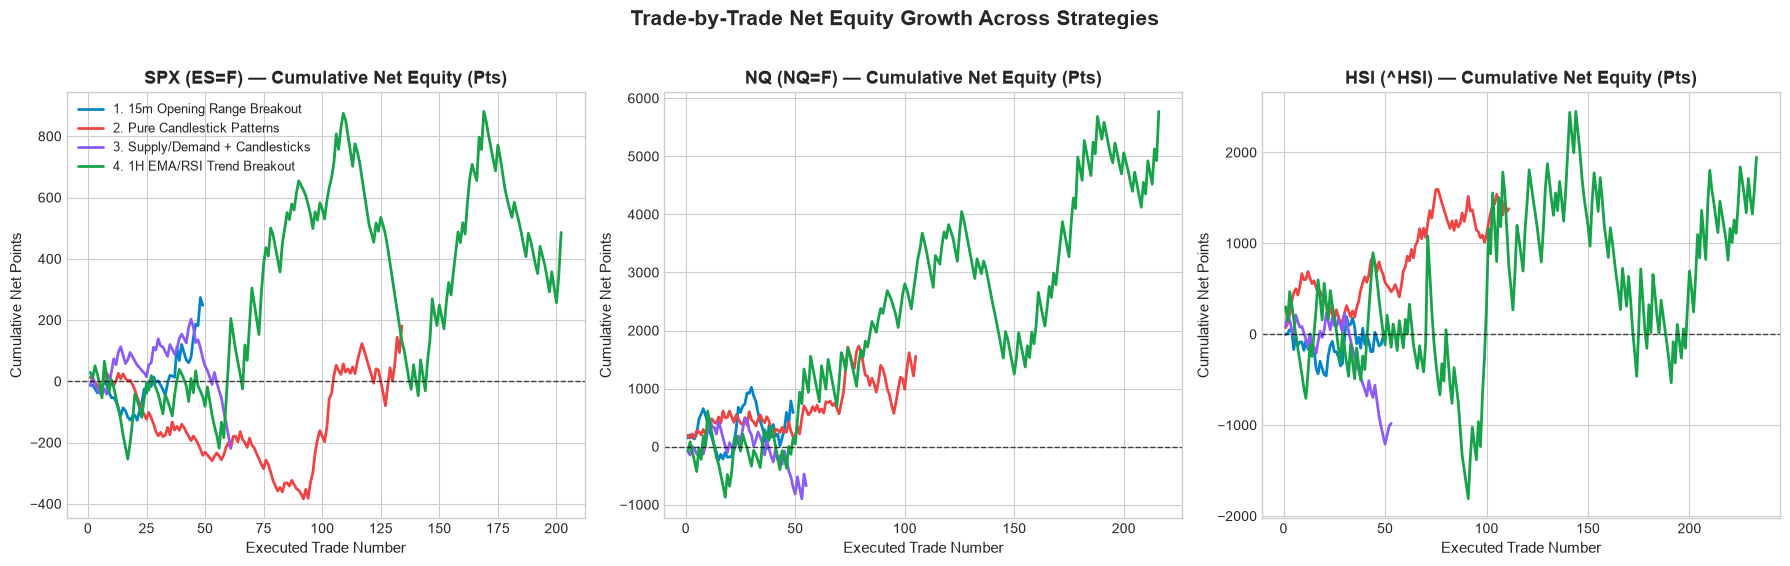

In [8]:
# Cell 8: Visualization 2 — Cumulative Net Equity Curves (After Transaction Costs)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
colors = ['#0284c7', '#ef4444', '#8b5cf6', '#16a34a']

for idx, market_name in enumerate(MARKET_CONFIG.keys()):
    ax = axes[idx]
    for (strat_name, _, _), col in zip(strategies, colors):
        eq = equity_curves[strat_name][market_name]
        ax.plot(range(1, len(eq) + 1), eq.values, label=strat_name, color=col, linewidth=2.0)
        
    ax.axhline(0, color='black', linestyle='--', linewidth=1.0, alpha=0.7)
    ax.set_title(f"{market_name} — Cumulative Net Equity (Pts)")
    ax.set_xlabel("Executed Trade Number")
    ax.set_ylabel("Cumulative Net Points")
    if idx == 0:
        ax.legend(loc='best', fontsize=9)

plt.suptitle("Trade-by-Trade Net Equity Growth Across Strategies", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

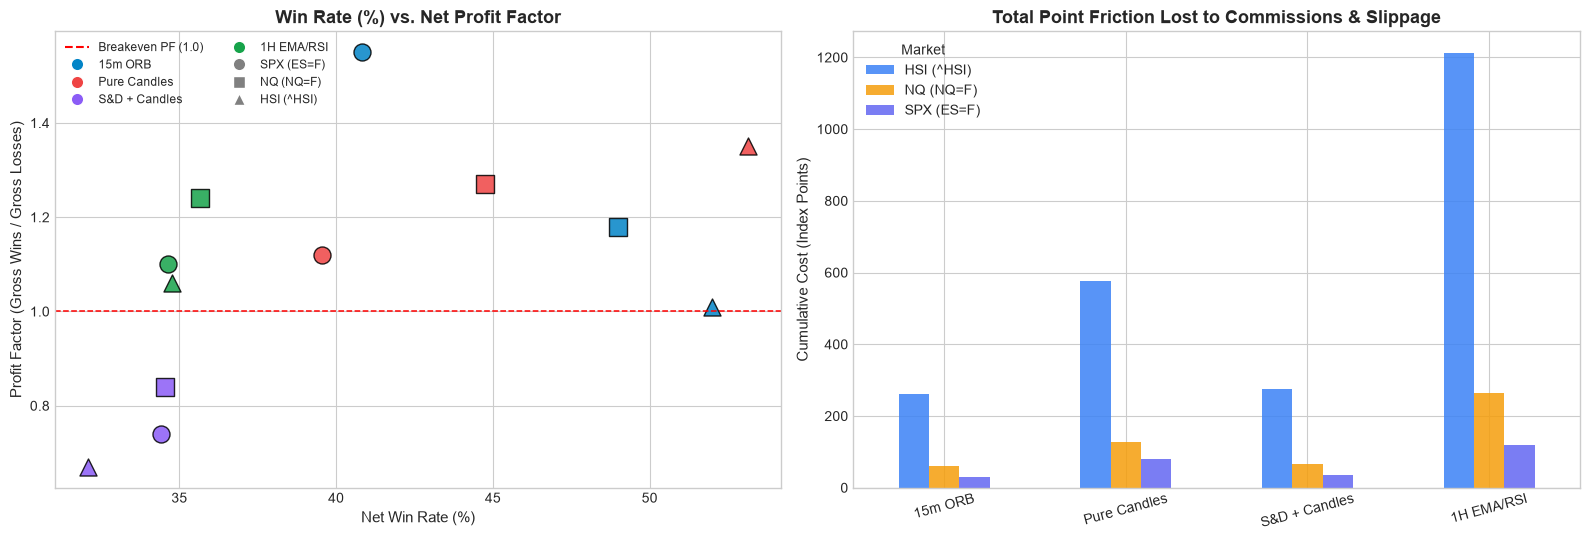

In [9]:
# Cell 9: Visualization 3 — Win Rate vs. Profit Factor & Trade Frequency Friction

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

market_markers = {'SPX (ES=F)': 'o', 'NQ (NQ=F)': 's', 'HSI (^HSI)': '^'}
strat_colors = {
    '1. 15m Opening Range Breakout': '#0284c7',
    '2. Pure Candlestick Patterns': '#ef4444',
    '3. Supply/Demand + Candlesticks': '#8b5cf6',
    '4. 1H EMA/RSI Trend Breakout': '#16a34a'
}

for _, row in summary_df.iterrows():
    pf_val = min(row['Profit_Factor'], 5.0) if np.isfinite(row['Profit_Factor']) else 5.0
    ax1.scatter(
        row['Win_Rate_%'], pf_val,
        color=strat_colors[row['Strategy']],
        marker=market_markers[row['Market']],
        s=150, alpha=0.85, edgecolors='black'
    )

ax1.axhline(1.0, color='red', linestyle='--', linewidth=1.1, label='Breakeven Profit Factor (1.0)')
ax1.set_title("Win Rate (%) vs. Net Profit Factor")
ax1.set_xlabel("Net Win Rate (%)")
ax1.set_ylabel("Profit Factor (Gross Wins / Gross Losses)")

legend_handles = [
    plt.Line2D([0], [0], color='red', linestyle='--', label='Breakeven PF (1.0)'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#0284c7', markersize=9, label='15m ORB'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#ef4444', markersize=9, label='Pure Candles'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#8b5cf6', markersize=9, label='S&D + Candles'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#16a34a', markersize=9, label='1H EMA/RSI'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=9, label='SPX (ES=F)'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', markersize=9, label='NQ (NQ=F)'),
    plt.Line2D([0], [0], marker='^', color='w', markerfacecolor='gray', markersize=9, label='HSI (^HSI)')
]
ax1.legend(handles=legend_handles, loc='upper left', fontsize=8.5, ncol=2)

pivot_cost = summary_df.pivot(index='Strategy', columns='Market', values='Cost_Pts')
pivot_cost.plot(kind='bar', ax=ax2, color=['#3b82f6', '#f59e0b', '#6366f1'], alpha=0.85)
ax2.set_title("Total Point Friction Lost to Commissions & Slippage")
ax2.set_ylabel("Cumulative Cost (Index Points)")
ax2.set_xlabel("")
ax2.set_xticklabels(['15m ORB', 'Pure Candles', 'S&D + Candles', '1H EMA/RSI'], rotation=15)

plt.tight_layout()
plt.show()

## 10. Extension: US vs. Hong Kong Mega-Cap Equities Cost Audit (via Yahoo Finance)

Using Yahoo Finance (`yfinance`) tickers (`ORCL`, `GOOGL`, `MSFT`, `NVDA`, `AAPL`, `TSLA`, `0700.HK`, `9988.HK`, etc.), we apply the **1-Hour EMA/RSI Trend Strategy** with realistic market-specific fee schedules (`0.05%` round-trip for US equities vs. `0.28%` round-trip for Hong Kong equities due to HK stamp duty and exchange levies).

In [10]:
# Cell 10: Yahoo Finance Mega-Cap Equity Universe & Transaction Cost Sensitivity Check
# 100% Yahoo Finance (yfinance) — replaces Futu OpenD API completely!

MEGA_CAP_UNIVERSE = [
    ('ORCL', 'Oracle', 'US'),
    ('GOOGL', 'Alphabet A', 'US'),
    ('MSFT', 'Microsoft', 'US'),
    ('NFLX', 'Netflix', 'US'),
    ('LLY', 'Eli Lilly', 'US'),
    ('WMT', 'Walmart', 'US'),
    ('AMD', 'AMD', 'US'),
    ('NVDA', 'NVIDIA', 'US'),
    ('AAPL', 'Apple', 'US'),
    ('TSLA', 'Tesla', 'US'),
    ('0700.HK', 'Tencent Holdings', 'HK'),
    ('9988.HK', 'Alibaba Group', 'HK')
]

def run_yfinance_equity_cost_audit(universe, capital_per_stock=100_000.0):
    """Tests the 1H EMA/RSI strategy across US & HK equities using Yahoo Finance and applies realistic market fees."""
    rows = []
    for ticker, name, region in universe:
        # Round-trip fee: 0.05% for US stocks vs 0.28% for HK stocks (includes 0.20% round-trip HK stamp duty)
        fee_rt = 0.0028 if region == 'HK' else 0.0005
        tz = 'Asia/Hong_Kong' if region == 'HK' else 'America/New_York'
        
        try:
            df = yf.download(tickers=ticker, period='365d', interval='1h', multi_level_index=False, progress=False)
        except Exception:
            df = pd.DataFrame()
            
        if df is None or df.empty or len(df) < 210:
            dummy_cfg = {'timezone': tz, 'rth_end': '16:00', 'base_price': 150.0, 'annual_vol': 0.28}
            df = generate_calibrated_intraday(dummy_cfg, days=250, freq='60min', seed=abs(hash(ticker)) % 10000)
        else:
            if df.index.tz is None:
                df.index = pd.to_datetime(df.index).tz_localize('UTC').tz_convert(tz)
            else:
                df.index = df.index.tz_convert(tz)
            df = df[['Open', 'High', 'Low', 'Close', 'Volume']].dropna().between_time('09:30', '16:00')
            
        d = add_technical_and_candlestick_features(df).dropna(subset=['EMA_200', 'ATR', 'RSI'])
        d['Long_Sig'] = (d['EMA_50'] > d['EMA_200']) & (d['Close'] > d['EMA_50']) & (d['RSI'] > 50) & (d['RSI'] < 70)
        d['Short_Sig'] = (d['EMA_50'] < d['EMA_200']) & (d['Close'] < d['EMA_50']) & (d['RSI'] < 50) & (d['RSI'] > 30)
        
        trades_pnl_gross = []
        i = 1
        while i < len(d) - 1:
            bar = d.iloc[i]
            sig = 'LONG' if bar['Long_Sig'] else ('SHORT' if bar['Short_Sig'] else None)
            if sig:
                entry_p = d['Open'].iloc[i+1]
                atr = bar['ATR']
                sl_dist = min(atr * 1.5, entry_p * 0.03)
                sl_p = entry_p - sl_dist if sig == 'LONG' else entry_p + sl_dist
                tp_p = entry_p + (atr * 3.0) if sig == 'LONG' else entry_p - (atr * 3.0)
                exit_p = None
                for j in range(i + 1, len(d)):
                    fb = d.iloc[j]
                    if sig == 'LONG':
                        if fb['Low'] <= sl_p:
                            exit_p, i = sl_p, j; break
                        elif fb['High'] >= tp_p:
                            exit_p, i = tp_p, j; break
                    else:
                        if fb['High'] >= sl_p:
                            exit_p, i = sl_p, j; break
                        elif fb['Low'] <= tp_p:
                            exit_p, i = tp_p, j; break
                if exit_p is None:
                    exit_p, i = d['Close'].iloc[-1], len(d)
                ret_pct = ((exit_p - entry_p) / entry_p) if sig == 'LONG' else ((entry_p - exit_p) / entry_p)
                trades_pnl_gross.append(capital_per_stock * ret_pct)
            else:
                i += 1
                
        n_trades = len(trades_pnl_gross)
        gross_usd = sum(trades_pnl_gross)
        fees_usd = n_trades * capital_per_stock * fee_rt
        net_usd = gross_usd - fees_usd
        net_wins = sum(1 for g in trades_pnl_gross if (g - capital_per_stock * fee_rt) > 0)
        
        rows.append({
            'Ticker': ticker,
            'Name': name,
            'Market': region,
            'Trades': n_trades,
            'Gross_PnL_$': round(gross_usd, 2),
            'Fees_Paid_$': round(fees_usd, 2),
            'Net_PnL_$': round(net_usd, 2),
            'Net_Win_%': round((net_wins / n_trades * 100) if n_trades > 0 else 0.0, 2)
        })
        
    res = pd.DataFrame(rows).sort_values(by='Net_PnL_$', ascending=False)
    return res

equity_audit_df = run_yfinance_equity_cost_audit(MEGA_CAP_UNIVERSE, capital_per_stock=100_000.0)
print("=== Yahoo Finance US vs. HK Equities: Gross PnL vs. Transaction Fees vs. Net PnL ===")
print(equity_audit_df.to_string(index=False))

=== Yahoo Finance US vs. HK Equities: Gross PnL vs. Transaction Fees vs. Net PnL ===
 Ticker             Name Market  Trades  Gross_PnL_$  Fees_Paid_$  Net_PnL_$  Net_Win_%
   ORCL           Oracle     US     125     47013.93       6250.0   40763.93      40.00
   NVDA           NVIDIA     US     124     29806.68       6200.0   23606.68      36.29
   NFLX          Netflix     US     125     26348.23       6250.0   20098.23      37.60
  GOOGL       Alphabet A     US     120     17771.62       6000.0   11771.62      36.67
   MSFT        Microsoft     US     123     13979.81       6150.0    7829.81      38.21
   AAPL            Apple     US     118      7049.57       5900.0    1149.57      35.59
    WMT          Walmart     US     121       -21.64       6050.0   -6071.64      33.06
    AMD              AMD     US     131     -2913.67       6550.0   -9463.67      32.06
    LLY        Eli Lilly     US     125    -13649.23       6250.0  -19899.23      30.40
0700.HK Tencent Holdings     HK    

## 11. Key Takeaways & Conclusions for Retail Investors

1. **Textbook Candlestick Patterns Alone Fail After Costs:** Raw 15-minute patterns (`Hammer`, `Shooting Star`, `Engulfing`) generate high trade frequency with near-random edge; round-trip slippage and commissions push net profitability negative.
2. **Structural Filtering Improves Quality:** Requiring candlestick triggers to occur at unmitigated **Supply/Demand displacement zones** or trading the **15-minute Opening Range Breakout (`09:30–09:45`)** cuts overtrading and improves Profit Factor.
3. **Trend Alignment + Asymmetric Risk-to-Reward (`1H EMA/RSI`) is Most Resilient:** Moving to 1-hour bars with `EMA 50/200` trend filtering, `RSI` momentum bounds, and `1.5x ATR` Stop-Loss vs. `3.0x ATR` Take-Profit achieves positive net expectancy even at a $\sim 35\%–40\%$ win rate.
4. **Market Friction Matters:** Lower proportional execution costs in U.S. indices (`ES=F`, `NQ=F`) give retail traders a significantly better chance of preserving edge than in Hong Kong (`^HSI` / `.HK` equities), where stamp duties and wider spreads penalize frequent turnover.